CSRT OBJECT TRACKING — GOOGLE COLAB


STUDENTS: Muresan Mihai Daniel &
          Morar Horea Razvan

This notebook tracks an object in a video using the CSRT algorithm from OpenCV.
The video file must be uploaded manually to the Colab file system before running.
Run cells from top to bottom. Do not skip any cell.

# CELL 1 — INSTALL DEPENDENCIES
Installs opencv-contrib-python-headless (includes CSRT tracker),
numpy, and matplotlib. The "headless" variant works in Colab
 since there is no display window available.
 This only needs to run once per Colab session.

In [1]:
!pip install opencv-contrib-python-headless numpy matplotlib -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.6/66.6 MB 8.3 MB/s eta 0:00:00


# CELL 2 — IMPORTS

Loads all required libraries into the session.
This cell must be run before any other code cell below it.

In [2]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
import time
from google.colab import files
from IPython.display import display, HTML

print("✅ All imports loaded successfully.")

✅ All imports loaded successfully.


# CELL 3 — SET VIDEO PATH AND VERIFY FILE

Set the VIDEO_PATH variable below to the path of your uploaded video.
If you uploaded the file directly to the Colab root, the path is just:
"/content/the_filename.mp4"

After running this cell, the video resolution, frame count,
FPS and duration will be printed so you can confirm it loaded correctly.

In [3]:
# Set the path to your uploaded video file here
VIDEO_PATH = "/content/video_final.mp4"

if not os.path.exists(VIDEO_PATH):
    print(f"ERROR: File not found at '{VIDEO_PATH}'")
    print("Make sure you uploaded the file to Colab and the path is correct.")
else:
    cap = cv2.VideoCapture(VIDEO_PATH)
    if not cap.isOpened():
        print(f"ERROR: OpenCV could not open '{VIDEO_PATH}'.")
        print("The file may be corrupted or in an unsupported format.")
    else:
        frame_w     = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        frame_h     = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        video_fps   = cap.get(cv2.CAP_PROP_FPS)
        duration    = total_frames / video_fps if video_fps > 0 else 0
        cap.release()

        print(f"Video file found and opened successfully.")
        print(f"  Path         : {VIDEO_PATH}")
        print(f"  Resolution   : {frame_w} x {frame_h} px")
        print(f"  Total frames : {total_frames}")
        print(f"  FPS          : {video_fps:.2f}")
        print(f"  Duration     : {duration:.1f} s")

Video file found and opened successfully.
  Path         : /content/video_final.mp4
  Resolution   : 1280 x 720 px
  Total frames : 493
  FPS          : 23.68
  Duration     : 20.8 s


# CELL 4 — INSPECT FIRST FRAME

Extracts the first frame from the video and displays it with a
coordinate grid overlaid every 100 pixels.

Your task: look at the displayed image and identify the object
you want to track. Note the bounding box coordinates:

*x, y* -> top-left corner of the box


*w* -> width of the box


*h* -> height of the box

You will enter these four values in Cell 5 before running the tracker.

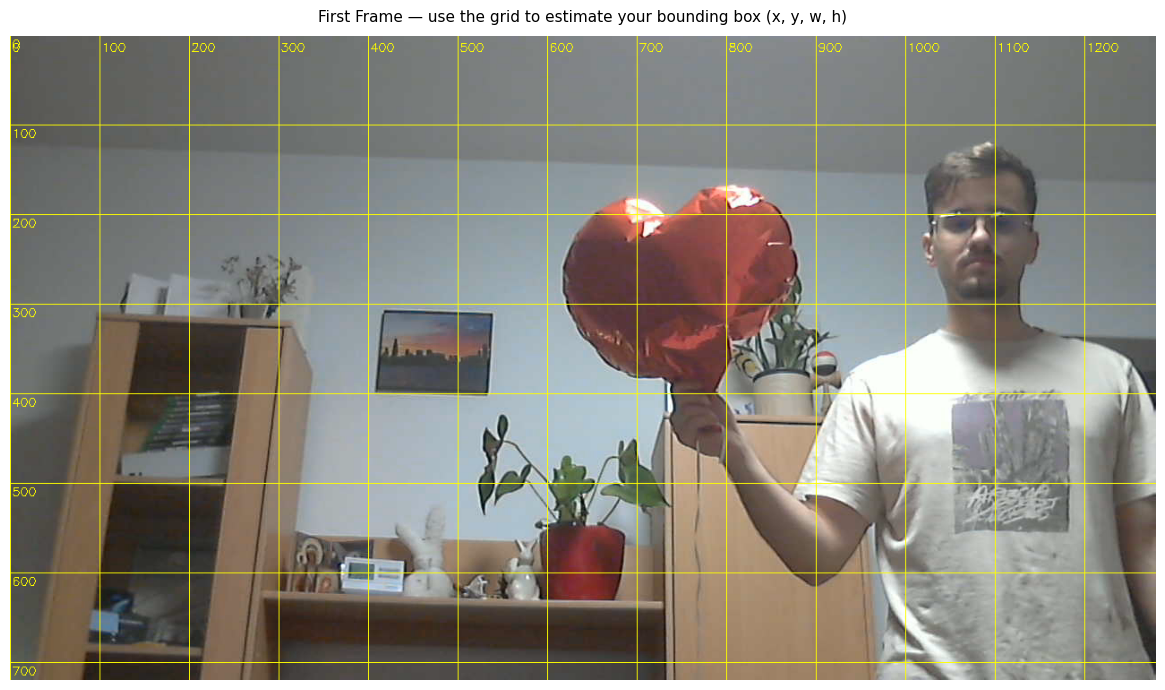

First frame displayed successfully.
  Resolution : 1280 x 720 px
Look at the image above and note the (x, y, w, h) of your object.
Enter those values in Cell 5 before running the tracker.


In [4]:
cap = cv2.VideoCapture(VIDEO_PATH)
ret, first_frame = cap.read()
cap.release()

if not ret:
    print("ERROR: Could not read the first frame. Check that the video file is valid.")
else:
    h, w = first_frame.shape[:2]
    frame_display = first_frame.copy()

    grid_color = (0, 255, 255)

    for x in range(0, w, 100):
        cv2.line(frame_display, (x, 0), (x, h), grid_color, 1)
        cv2.putText(frame_display, str(x), (x + 2, 18),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, grid_color, 1)
    for y in range(0, h, 100):
        cv2.line(frame_display, (0, y), (w, y), grid_color, 1)
        cv2.putText(frame_display, str(y), (2, y + 14),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, grid_color, 1)

    plt.figure(figsize=(13, 7))
    plt.imshow(cv2.cvtColor(frame_display, cv2.COLOR_BGR2RGB))
    plt.title("First Frame — use the grid to estimate your bounding box (x, y, w, h)",
              fontsize=11, pad=10)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print("First frame displayed successfully.")
    print(f"  Resolution : {w} x {h} px")
    print("Look at the image above and note the (x, y, w, h) of your object.")
    print("Enter those values in Cell 5 before running the tracker.")

# CELL 5 — SET BOUNDING BOX AND RUN TRACKER

Edit the BBOX variable below with the coordinates you identified in Cell 4.


**Format: (x, y, w, h)**


*x, y* -> top-left corner of the bounding box


*w* -> width of the bounding box


*h* -> height of the bounding box

While the tracker runs you will see:
- A preview of the initial bounding box on frame 0
- A progress bar printed every 50 frames
- A preview frame with the bounding box drawn every 30 frames
so you can visually confirm the tracker is following the object

The variable preview_every controls how often preview frames are shown.
Lower value = more previews (slower). Higher value = fewer previews (faster).

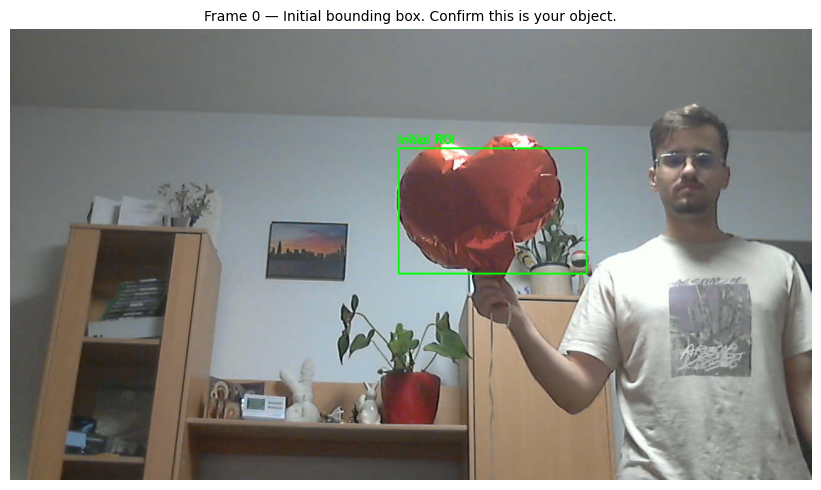

Starting CSRT tracker. Total frames to process: 493

  [                    ]   0.2%  frame 1/493  status: tracked
  [==                  ]  10.1%  frame 50/493  status: tracked
  [====                ]  20.3%  frame 100/493  status: tracked


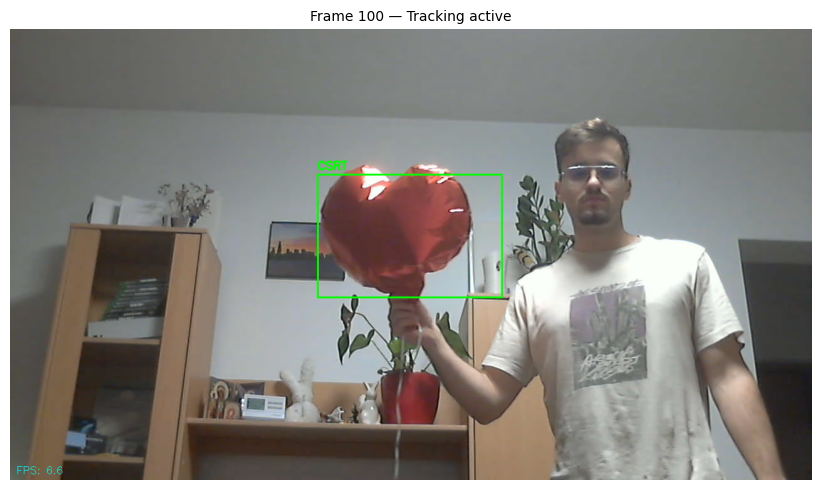

  [======              ]  30.4%  frame 150/493  status: tracked
  [========            ]  40.6%  frame 200/493  status: tracked


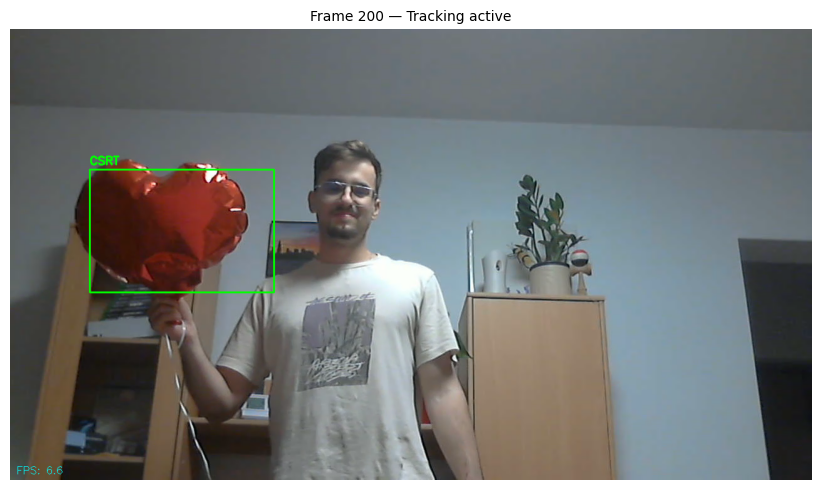

  [==========          ]  50.7%  frame 250/493  status: tracked
  [============        ]  60.9%  frame 300/493  status: tracked


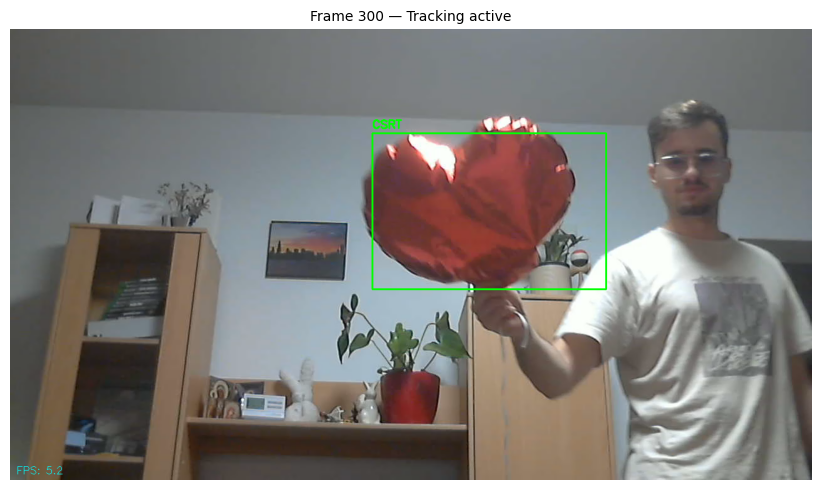

  [==============      ]  71.0%  frame 350/493  status: tracked
  [================    ]  81.1%  frame 400/493  status: tracked


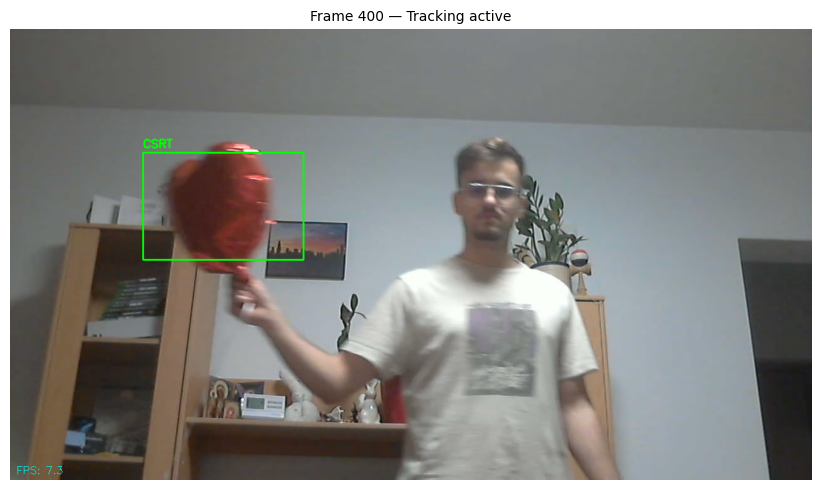

  [==================  ]  91.3%  frame 450/493  status: tracked

Tracking complete.
  Tracked : 492 / 492 frames
  Lost    : 0 frames
  Rate    : 100.0%
  Avg FPS : 6.2


In [5]:
# Set your bounding box here based on what you saw in Cell 4
BBOX = (620, 190, 300, 200)   # <-- change to (x, y, w, h) of your object

# How often to show a preview frame (every N frames)
PREVIEW_EVERY = 100


def show_frame_inline(frame, title=""):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(9, 5))
    plt.imshow(rgb)
    plt.title(title, fontsize=10)
    plt.axis('off')
    plt.tight_layout()
    plt.show()


def run_csrt_tracker(video_path, bbox, preview_every=30):
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise IOError(f"Cannot open video: {video_path}")

    ret, first_frame = cap.read()
    if not ret:
        raise IOError("Cannot read first frame.")

    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Show initial bounding box on frame 0
    preview = first_frame.copy()
    x, y, bw, bh = [int(v) for v in bbox]
    cv2.rectangle(preview, (x, y), (x + bw, y + bh), (0, 255, 0), 2)
    cv2.putText(preview, "Initial ROI", (x, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    show_frame_inline(preview, "Frame 0 — Initial bounding box. Confirm this is your object.")

    tracker = cv2.TrackerCSRT_create()
    tracker.init(first_frame, bbox)

    fps_list      = []
    frame_times   = []
    success_flags = []
    frame_index   = 0

    print(f"Starting CSRT tracker. Total frames to process: {total}\n")

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        t0 = time.time()
        success, bbox_pred = tracker.update(frame)
        elapsed = time.time() - t0

        fps_list.append(1.0 / (elapsed + 1e-9))
        frame_times.append(elapsed)
        success_flags.append(success)

        # Progress bar every 50 frames
        if (frame_index + 1) % 50 == 0 or frame_index == 0:
            pct = (frame_index + 1) / max(total, 1) * 100
            filled = int(pct // 5)
            bar = ("=" * filled).ljust(20)
            status = "tracked" if success else "lost"
            print(f"  [{bar}] {pct:5.1f}%  frame {frame_index + 1}/{total}  status: {status}")

        # Visual preview every N frames
        if (frame_index + 1) % preview_every == 0:
            preview = frame.copy()
            if success:
                px, py, pw, ph = [int(v) for v in bbox_pred]
                cv2.rectangle(preview, (px, py), (px + pw, py + ph), (0, 255, 0), 2)
                cv2.putText(preview, "CSRT", (px, py - 8),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
                label = f"Frame {frame_index + 1} — Tracking active"
            else:
                cv2.putText(preview, "TRACKING LOST", (30, 50),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 255), 2)
                label = f"Frame {frame_index + 1} — Tracking lost"

            cv2.putText(preview, f"FPS: {fps_list[-1]:.1f}",
                        (10, preview.shape[0] - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 0), 1)
            show_frame_inline(preview, label)

        frame_index += 1

    cap.release()

    total_time    = sum(frame_times)
    tracked_f     = sum(success_flags)
    lost_f        = frame_index - tracked_f
    time_tracking = sum(t for t, s in zip(frame_times, success_flags) if s)
    time_lost     = sum(t for t, s in zip(frame_times, success_flags) if not s)

    results = {
        "total_frames"   : frame_index,
        "total_time_s"   : total_time,
        "tracked_frames" : tracked_f,
        "lost_frames"    : lost_f,
        "tracking_rate_%": 100 * tracked_f / max(frame_index, 1),
        "time_tracking_s": time_tracking,
        "time_lost_s"    : time_lost,
        "avg_fps"        : np.mean(fps_list) if fps_list else 0,
        "min_fps"        : np.min(fps_list)  if fps_list else 0,
        "max_fps"        : np.max(fps_list)  if fps_list else 0,
    }

    return results, fps_list, success_flags, frame_times


results, fps_list, success_flags, frame_times = run_csrt_tracker(
    VIDEO_PATH, BBOX, preview_every=PREVIEW_EVERY
)

print("\nTracking complete.")
print(f"  Tracked : {results['tracked_frames']} / {results['total_frames']} frames")
print(f"  Lost    : {results['lost_frames']} frames")
print(f"  Rate    : {results['tracking_rate_%']:.1f}%")
print(f"  Avg FPS : {results['avg_fps']:.1f}")

# CELL 6 — PLOT METRICS

Generates a 3-panel analysis figure:


Left: FPS over time, showing how fast the tracker ran per frame


Center : Pie chart showing how much total time was spent tracking vs lost


Right : Summary table with all key numbers

The figure is also saved as "tracking_metrics.png" in /content/.
To download it, open the Files panel on the left sidebar,
right-click the file, and select Download.

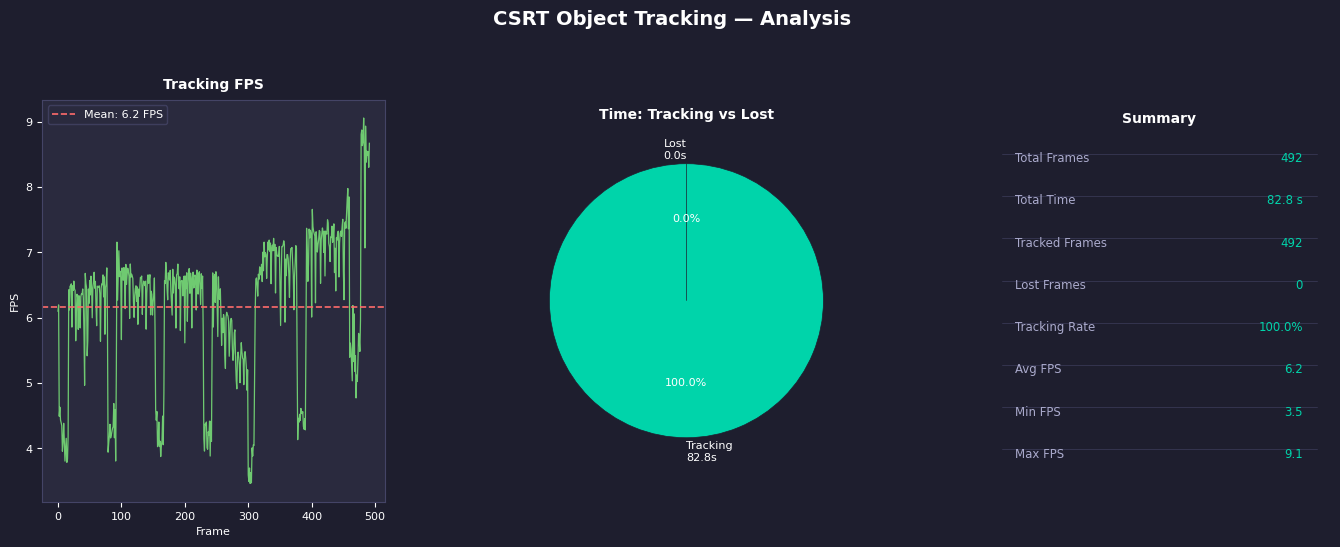

Metrics plotted successfully.
Figure saved to /content/tracking_metrics.png
To download: open the Files panel on the left, right-click the file, select Download.


In [6]:
def plot_metrics(results, fps_list, success_flags):
    BG     = '#1e1e2e'
    PANEL  = '#2a2a3e'
    ACCENT = '#00d4aa'
    WARN   = '#ff6b6b'
    TXT    = 'white'
    SUBTLE = '#aaaacc'

    fig = plt.figure(figsize=(14, 6), facecolor=BG)
    gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.38,
                            left=0.05, right=0.97, top=0.80, bottom=0.13)

    def style_ax(ax, title):
        ax.set_facecolor(PANEL)
        ax.set_title(title, color=TXT, fontsize=10, fontweight='bold', pad=8)
        ax.tick_params(colors=TXT, labelsize=8)
        for spine in ax.spines.values():
            spine.set_edgecolor('#444466')
        ax.xaxis.label.set_color(TXT)
        ax.yaxis.label.set_color(TXT)

    # FPS over time
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(fps_list, color='#77dd77', linewidth=0.9, alpha=0.9)
    ax1.axhline(np.mean(fps_list), color=WARN, linestyle='--',
                linewidth=1.2, label=f"Mean: {np.mean(fps_list):.1f} FPS")
    ax1.set_xlabel("Frame", fontsize=8)
    ax1.set_ylabel("FPS", fontsize=8)
    ax1.legend(fontsize=8, labelcolor=TXT, facecolor=PANEL, edgecolor='#444466')
    style_ax(ax1, "Tracking FPS")

    # Pie chart
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.set_facecolor(BG)
    t_track = results["time_tracking_s"]
    t_lost  = results["time_lost_s"]
    wedges, texts, autotexts = ax2.pie(
        [t_track, t_lost],
        labels=[f"Tracking\n{t_track:.1f}s", f"Lost\n{t_lost:.1f}s"],
        colors=[ACCENT, WARN],
        autopct='%1.1f%%',
        startangle=90,
        textprops={'color': TXT, 'fontsize': 8},
        wedgeprops={'linewidth': 0.5, 'edgecolor': BG}
    )
    for at in autotexts:
        at.set_fontsize(8)
        at.set_color(TXT)
    ax2.set_title("Time: Tracking vs Lost", color=TXT,
                  fontsize=10, fontweight='bold', pad=8)

    # Summary table
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.set_facecolor(PANEL)
    ax3.axis('off')

    rows = [
        ("Total Frames",   str(results["total_frames"])),
        ("Total Time",     f"{results['total_time_s']:.1f} s"),
        ("Tracked Frames", str(results["tracked_frames"])),
        ("Lost Frames",    str(results["lost_frames"])),
        ("Tracking Rate",  f"{results['tracking_rate_%']:.1f}%"),
        ("Avg FPS",        f"{results['avg_fps']:.1f}"),
        ("Min FPS",        f"{results['min_fps']:.1f}"),
        ("Max FPS",        f"{results['max_fps']:.1f}"),
    ]

    ax3.text(0.5, 0.97, "Summary", color=TXT, fontsize=10,
             fontweight='bold', ha='center', va='top', transform=ax3.transAxes)

    y = 0.87
    for label, value in rows:
        ax3.text(0.08, y, label, color=SUBTLE, fontsize=8.5,
                 va='top', transform=ax3.transAxes)
        ax3.text(0.92, y, value, color=ACCENT, fontsize=8.5,
                 va='top', ha='right', transform=ax3.transAxes)
        ax3.axhline(y - 0.005, color='#444466', linewidth=0.4,
                    xmin=0.04, xmax=0.96)
        y -= 0.105

    fig.suptitle("CSRT Object Tracking — Analysis",
                 color=TXT, fontsize=14, fontweight='bold', y=0.95)

    plt.savefig("/content/tracking_metrics.png", dpi=150,
                bbox_inches='tight', facecolor=BG)
    plt.show()

    print("Metrics plotted successfully.")
    print("Figure saved to /content/tracking_metrics.png")
    print("To download: open the Files panel on the left, right-click the file, select Download.")


plot_metrics(results, fps_list, success_flags)